In [1]:
# Download all relevant Cofacts tables
#
# Tables we need for the thesis:
#   articles        — every piece of disinformation submitted to the platform
#   replies         — fact-checker verdicts (RUMOR / NOT_RUMOR / OPINIONATED)
#   article_replies — joins articles to replies (the verdict connection)
#   reply_requests  — how many users asked for the same piece to be checked
#   analytics       — daily view counts per article (measures virality)
#
# Tables we don't need:
#   article_hyperlinks, reply_hyperlinks — URL metadata, not relevant
#   article_reply_feedbacks — user ratings of replies, useful later
#   anonymized_usrs — user accounts, not needed

from datasets import load_dataset
import pandas as pd

print("Downloading articles...")
articles_ds = load_dataset(
    "Cofacts/line-msg-fact-check-tw",
    "articles",
    trust_remote_code=True
)
articles = articles_ds['train'].to_pandas()
print(f"  articles: {len(articles):,} rows")

print("Downloading replies...")
replies_ds = load_dataset(
    "Cofacts/line-msg-fact-check-tw",
    "replies",
    trust_remote_code=True
)
replies = replies_ds['train'].to_pandas()
print(f"  replies: {len(replies):,} rows")

print("Downloading article_replies...")
article_replies_ds = load_dataset(
    "Cofacts/line-msg-fact-check-tw",
    "article_replies",
    trust_remote_code=True
)
article_replies = article_replies_ds['train'].to_pandas()
print(f"  article_replies: {len(article_replies):,} rows")

print("Downloading reply_requests...")
reply_requests_ds = load_dataset(
    "Cofacts/line-msg-fact-check-tw",
    "reply_requests",
    trust_remote_code=True
)
reply_requests = reply_requests_ds['train'].to_pandas()
print(f"  reply_requests: {len(reply_requests):,} rows")

print("Downloading analytics...")
analytics_ds = load_dataset(
    "Cofacts/line-msg-fact-check-tw",
    "analytics",
    trust_remote_code=True
)
analytics = analytics_ds['train'].to_pandas()
print(f"  analytics: {len(analytics):,} rows")

print("\nAll tables loaded.")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Cofacts/line-msg-fact-check-tw' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


README.md:   0%|          | 0.00/19.6k [00:00<?, ?B/s]

articles.csv.zip:   0%|          | 0.00/100M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/291064 [00:00<?, ? examples/s]

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Cofacts/line-msg-fact-check-tw' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


...

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'Cofacts/line-msg-fact-check-tw' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  reply_requests: 639,593 rows


analytics.csv.zip:   0%|          | 0.00/181M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/15238084 [00:00<?, ? examples/s]

  analytics: 15,238,084 rows

All tables loaded.


In [2]:
import os
from dotenv import load_dotenv

load_dotenv(os.path.join(os.path.dirname(os.getcwd()), '.env'))
print(f"HF_TOKEN loaded: {'yes' if os.getenv('HF_TOKEN') else 'no'}")

HF_TOKEN loaded: yes


In [ ]:
import os
os.makedirs("cofacts_data", exist_ok=True)

articles.to_csv("cofacts_data/articles.csv", index=False)
replies.to_csv("cofacts_data/replies.csv", index=False)
article_replies.to_csv("cofacts_data/article_replies.csv", index=False)
reply_requests.to_csv("cofacts_data/reply_requests.csv", index=False)
analytics.to_csv("cofacts_data/analytics.csv", index=False)

print("Saved to ./cofacts_data/")

In [ ]:
# Load data into pandas
import pandas as pd

articles = pd.read_csv("{path_to_data}/cofacts_data/articles.csv")
analytics = pd.read_csv("{path_to_data}/cofacts_data/analytics.csv")
replies = pd.read_csv("{path_to_data}/cofacts_data/replies.csv")
article_replies = pd.read_csv("{path_to_data}/cofacts_data/article_replies.csv")
reply_requests = pd.read_csv("{path_to_data}/cofacts_data/reply_requests.csv")

In [6]:
# Join tables and parse dates
#
# We build one master dataframe:
# One row per article, with:
#   - the article text and submission date
#   - how many users flagged it (reply_requests count = virality proxy)
#   - the fact-checker verdict (RUMOR / NOT_RUMOR / OPINIONATED)
#   - response time (submitted → first reply)

articles['createdAt'] = pd.to_datetime(articles['createdAt'], format='ISO8601', utc=True)
replies['createdAt'] = pd.to_datetime(replies['createdAt'], format='ISO8601', utc=True)
article_replies['createdAt'] = pd.to_datetime(article_replies['createdAt'], format='ISO8601', utc=True)
reply_requests['createdAt'] = pd.to_datetime(reply_requests['createdAt'], format='ISO8601', utc=True)

# How many users flagged each article (virality proxy)
flag_counts = (reply_requests
    .groupby('articleId')
    .size()
    .reset_index(name='flag_count'))

# First verdict per article (earliest article_reply)
first_verdict = (article_replies
    .sort_values('createdAt')
    .groupby('articleId')
    .first()
    .reset_index()[['articleId', 'replyId', 'replyType', 'createdAt']]
    .rename(columns={'createdAt': 'first_reply_at', 'replyType': 'verdict'}))

# Merge everything
master = (articles
    .merge(flag_counts, left_on='id', right_on='articleId', how='left')
    .merge(first_verdict, left_on='id', right_on='articleId', how='left')
)

master['flag_count'] = master['flag_count'].fillna(0).astype(int)
master['has_verdict'] = master['verdict'].notnull()
master['response_hours'] = (
    (master['first_reply_at'] - master['createdAt'])
    .dt.total_seconds() / 3600
)

# Derived time columns used by plotting cells
master['year_month'] = master['createdAt'].dt.to_period('M')
master['year'] = master['createdAt'].dt.year

print(f"Master dataframe: {len(master):,} articles")
print(f"Date range: {master['createdAt'].min().date()} – "
      f"{master['createdAt'].max().date()}")
print(f"\nVerdict distribution:")
print(master['verdict'].value_counts(dropna=False))
print(f"\nArticles with at least one verdict: "
      f"{master['has_verdict'].sum():,} "
      f"({master['has_verdict'].mean()*100:.1f}%)")

Master dataframe: 77,524 articles
Date range: 2016-12-17 – 2026-04-01

Verdict distribution:
verdict
NaN            56468
RUMOR          11606
NOT_ARTICLE     3864
NOT_RUMOR       3277
OPINIONATED     2309
Name: count, dtype: int64

Articles with at least one verdict: 21,056 (27.2%)


/var/folders/dn/35xp5kp105jfh9lr1rc942140000gn/T/ipykernel_48939/1913443812.py:43: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  master['year_month'] = master['createdAt'].dt.to_period('M')


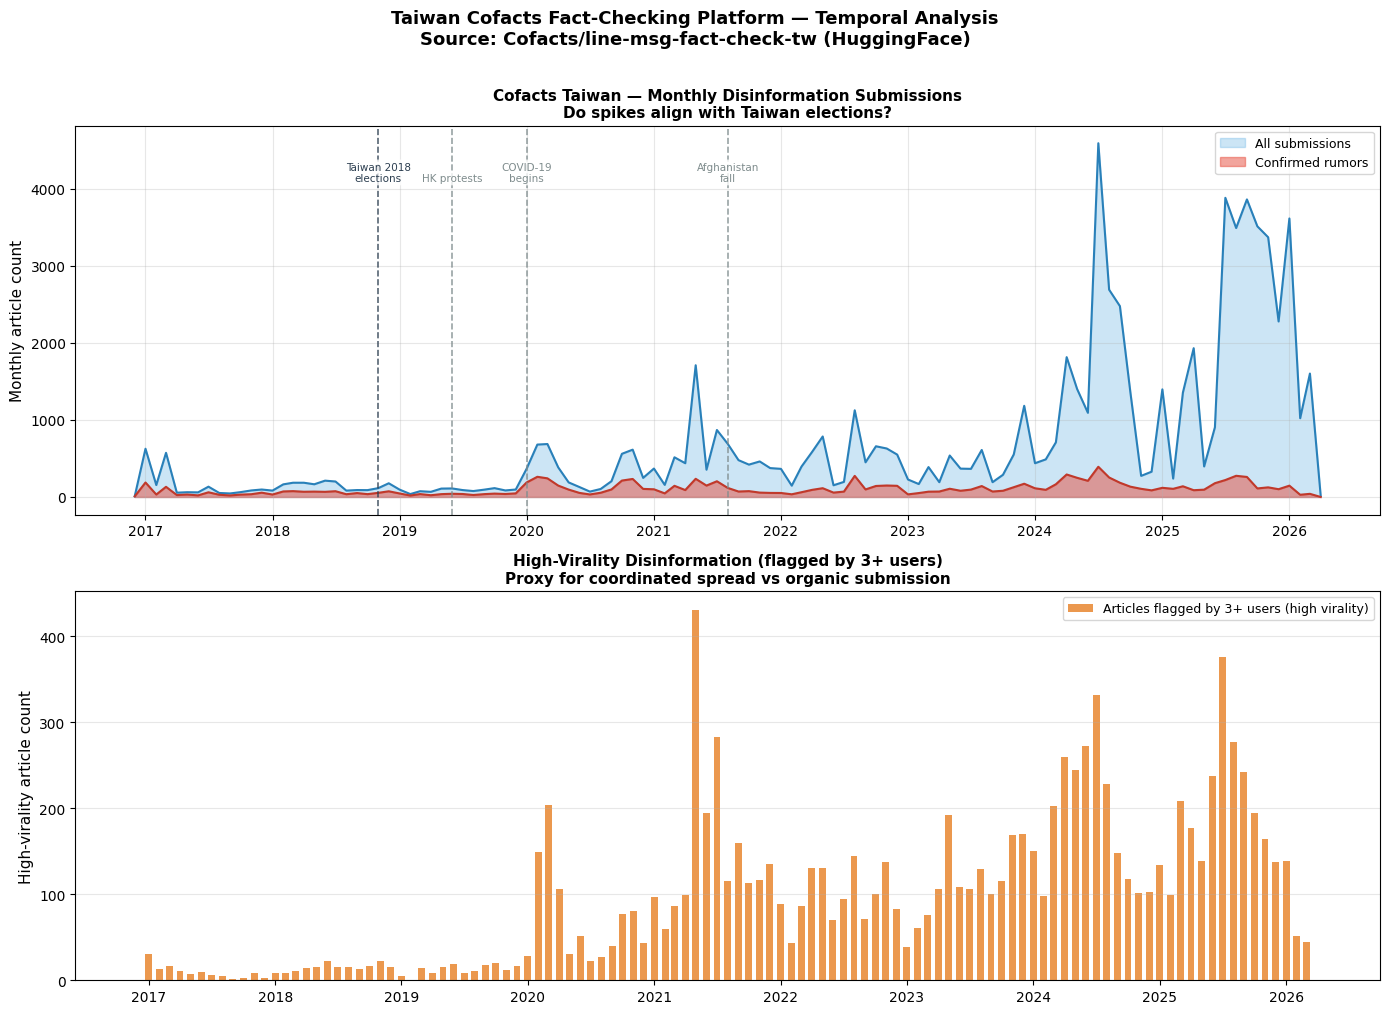

Submission counts in 90-day windows around Taiwan elections:

  2018 elections:
    90-day window submissions: 617
    Prior 6-month baseline:    1,023
    Uplift ratio:              1.21x
    Confirmed rumors in window: 281

  2020 elections:
    90-day window submissions: 2,183
    Prior 6-month baseline:    552
    Uplift ratio:              7.91x
    Confirmed rumors in window: 887


In [7]:
# Volume over time: when did disinformation spike?
#
# This is your first key finding. If submission volume spikes around
# Taiwan's 2018 and 2020 elections, that is behavioral evidence that
# disinformation campaigns intensify around political events.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

monthly_vol = (master
    .groupby('year_month')
    .agg(
        total=('id', 'count'),
        rumor=('verdict', lambda x: (x == 'RUMOR').sum()),
        flagged_high=('flag_count', lambda x: (x >= 3).sum())
    )
    .reset_index()
)
monthly_vol['year_month_dt'] = monthly_vol['year_month'].dt.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Top: total submissions + rumor verdicts
ax = axes[0]
ax.fill_between(monthly_vol['year_month_dt'],
                monthly_vol['total'],
                alpha=0.25, color='#3498db', label='All submissions')
ax.plot(monthly_vol['year_month_dt'], monthly_vol['total'],
        color='#2980b9', linewidth=1.5)
ax.fill_between(monthly_vol['year_month_dt'],
                monthly_vol['rumor'],
                alpha=0.5, color='#e74c3c', label='Confirmed rumors')
ax.plot(monthly_vol['year_month_dt'], monthly_vol['rumor'],
        color='#c0392b', linewidth=1.5)

# Mark elections and key events
events = {
    '2018-11': ('Taiwan 2018\nelections', '#2c3e50'),
    '2020-01': ('Taiwan 2020\nelections', '#2c3e50'),
    '2019-06': ('HK protests', '#7f8c8d'),
    '2020-01': ('COVID-19\nbegins', '#7f8c8d'),
    '2021-08': ('Afghanistan\nfall', '#7f8c8d'),
}
for date_str, (label_text, color) in events.items():
    event_dt = pd.Timestamp(date_str).tz_localize('UTC')
    ax.axvline(event_dt, color=color, linestyle='--',
               linewidth=1.2, alpha=0.8)
    ax.text(event_dt, ax.get_ylim()[1] * 0.85,
            label_text, fontsize=7.5, ha='center',
            color=color,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                      alpha=0.8, edgecolor='none'))

ax.set_ylabel('Monthly article count', fontsize=11)
ax.set_title('Cofacts Taiwan — Monthly Disinformation Submissions\n'
             'Do spikes align with Taiwan elections?',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# Bottom: highly-flagged articles (3+ users flagging same content)
ax2 = axes[1]
ax2.bar(monthly_vol['year_month_dt'],
        monthly_vol['flagged_high'],
        width=20, color='#e67e22', alpha=0.8,
        label='Articles flagged by 3+ users (high virality)')
ax2.set_ylabel('High-virality article count', fontsize=11)
ax2.set_title('High-Virality Disinformation (flagged by 3+ users)\n'
              'Proxy for coordinated spread vs organic submission',
              fontsize=11, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3, axis='y')

plt.suptitle('Taiwan Cofacts Fact-Checking Platform — Temporal Analysis\n'
             'Source: Cofacts/line-msg-fact-check-tw (HuggingFace)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Print election window statistics
print("Submission counts in 90-day windows around Taiwan elections:")
for election_date, name in [('2018-11-24', '2018 elections'),
                              ('2020-01-11', '2020 elections')]:
    center = pd.Timestamp(election_date, tz='UTC')
    window = master[
        (master['createdAt'] >= center - pd.Timedelta(days=90)) &
        (master['createdAt'] <= center + pd.Timedelta(days=90))
    ]
    baseline = master[
        (master['createdAt'] >= center - pd.Timedelta(days=270)) &
        (master['createdAt'] < center - pd.Timedelta(days=90))
    ]
    print(f"\n  {name}:")
    print(f"    90-day window submissions: {len(window):,}")
    print(f"    Prior 6-month baseline:    {len(baseline):,}")
    print(f"    Uplift ratio:              "
          f"{len(window)/max(len(baseline)/2,1):.2f}x")
    print(f"    Confirmed rumors in window: "
          f"{(window['verdict']=='RUMOR').sum():,}")

/var/folders/dn/35xp5kp105jfh9lr1rc942140000gn/T/ipykernel_48939/1571268630.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(response_by_year, labels=years_to_plot,


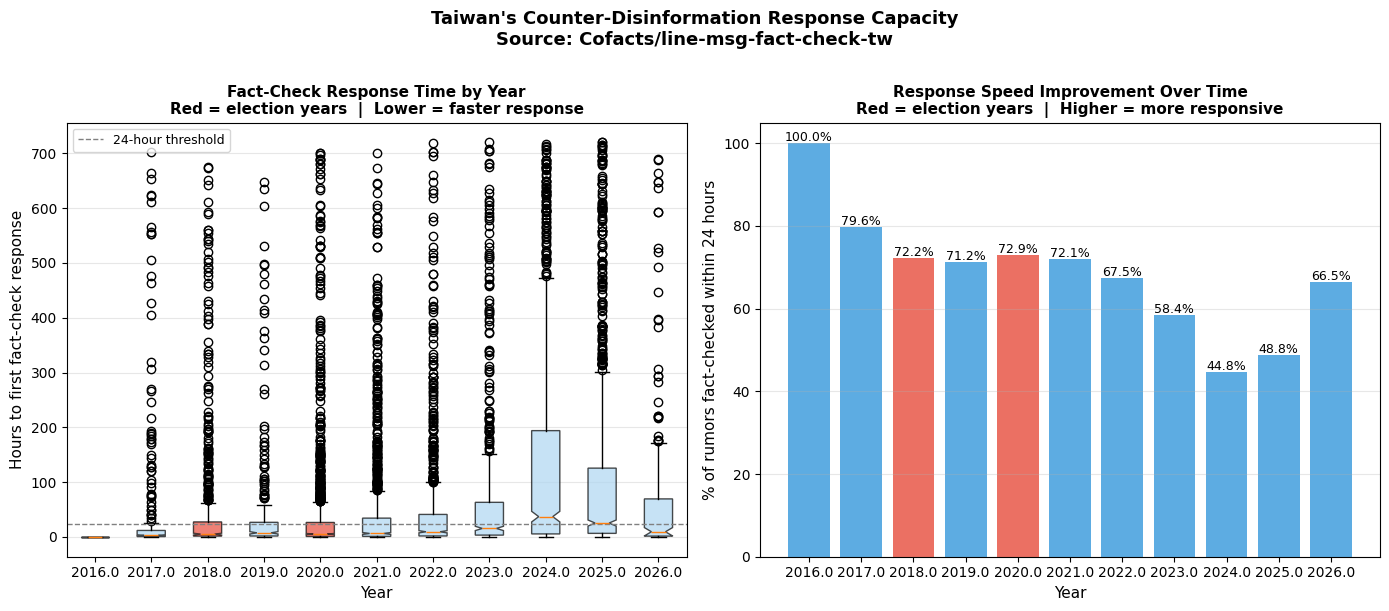

Median response time (hours) by year:
year
2016.0     0.0
2017.0     2.9
2018.0     5.2
2019.0     7.6
2020.0     5.4
2021.0     6.4
2022.0     9.5
2023.0    15.6
2024.0    37.1
2025.0    25.4
2026.0     9.5

% responded within 24 hours by year:
year
2016.0    100.0
2017.0     79.6
2018.0     72.2
2019.0     71.2
2020.0     72.9
2021.0     72.1
2022.0     67.5
2023.0     58.4
2024.0     44.8
2025.0     48.8
2026.0     66.5


In [8]:
# The resilience finding: how fast did Taiwan respond?
#
# If response times got FASTER between 2018 and 2020, that is quantitative
# evidence that Taiwan's counter-disinformation infrastructure improved.

# Filter to rumor verdicts only (most relevant)
rumors = master[master['verdict'] == 'RUMOR'].copy()
rumors = rumors[rumors['response_hours'].between(0, 720)]  # cap at 30 days

# Response time by year
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
years_to_plot = sorted(rumors['year'].dropna().unique())
response_by_year = [
    rumors[rumors['year'] == yr]['response_hours'].dropna().values
    for yr in years_to_plot
]

bp = ax.boxplot(response_by_year, labels=years_to_plot,
                patch_artist=True, notch=True)

colors = ['#e74c3c' if yr in [2018, 2020] else '#aed6f1'
          for yr in years_to_plot]
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.axhline(24, color='gray', linestyle='--', linewidth=1,
           label='24-hour threshold')
ax.set_ylabel('Hours to first fact-check response', fontsize=11)
ax.set_xlabel('Year', fontsize=11)
ax.set_title('Fact-Check Response Time by Year\n'
             'Red = election years  |  Lower = faster response',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(alpha=0.3, axis='y')

# Percentage responded within 24 hours by year
ax2 = axes[1]
fast_response = (rumors.groupby('year')
    .apply(lambda x: (x['response_hours'] <= 24).mean() * 100)
    .reset_index(name='pct_within_24h'))

bar_colors = ['#e74c3c' if yr in [2018, 2020] else '#3498db'
              for yr in fast_response['year']]
ax2.bar(fast_response['year'].astype(str),
        fast_response['pct_within_24h'],
        color=bar_colors, alpha=0.8)

for i, row in fast_response.iterrows():
    ax2.text(i, row['pct_within_24h'] + 0.5,
             f"{row['pct_within_24h']:.1f}%",
             ha='center', fontsize=9)

ax2.set_ylabel('% of rumors fact-checked within 24 hours', fontsize=11)
ax2.set_xlabel('Year', fontsize=11)
ax2.set_title('Response Speed Improvement Over Time\n'
              'Red = election years  |  Higher = more responsive',
              fontsize=11, fontweight='bold')
ax2.grid(alpha=0.3, axis='y')

plt.suptitle("Taiwan's Counter-Disinformation Response Capacity\n"
             "Source: Cofacts/line-msg-fact-check-tw",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Print the key statistics
print("Median response time (hours) by year:")
print(rumors.groupby('year')['response_hours']
      .median().round(1).to_string())
print("\n% responded within 24 hours by year:")
print(fast_response.set_index('year')['pct_within_24h']
      .round(1).to_string())

In [9]:
# 2018 vs 2020 direct comparison
#
# Taiwan failed to counter disinformation in 2018 but succeeded in 2020.

from scipy import stats

# 90-day pre-election windows
election_2018 = pd.Timestamp('2018-11-24', tz='UTC')
election_2020 = pd.Timestamp('2020-01-11', tz='UTC')

pre_2018 = master[
    (master['createdAt'] >= election_2018 - pd.Timedelta(days=90)) &
    (master['createdAt'] <= election_2018)
].copy()

pre_2020 = master[
    (master['createdAt'] >= election_2020 - pd.Timedelta(days=90)) &
    (master['createdAt'] <= election_2020)
].copy()

print("=" * 60)
print("2018 vs 2020 PRE-ELECTION DISINFORMATION COMPARISON")
print("=" * 60)

metrics = {
    'Total submissions':
        (len(pre_2018), len(pre_2020)),
    'Confirmed rumors (RUMOR verdict)':
        ((pre_2018['verdict']=='RUMOR').sum(),
         (pre_2020['verdict']=='RUMOR').sum()),
    'High-virality (3+ flags)':
        ((pre_2018['flag_count']>=3).sum(),
         (pre_2020['flag_count']>=3).sum()),
    'Median response time (hrs)':
        (pre_2018[pre_2018['verdict']=='RUMOR']['response_hours']
         .median().round(1),
         pre_2020[pre_2020['verdict']=='RUMOR']['response_hours']
         .median().round(1)),
    '% checked within 24hrs':
        ((pre_2018[pre_2018['verdict']=='RUMOR']['response_hours']<=24)
         .mean()*100,
         (pre_2020[pre_2020['verdict']=='RUMOR']['response_hours']<=24)
         .mean()*100),
}

print(f"\n{'Metric':<40} {'2018':>10} {'2020':>10}")
print("-" * 62)
for metric, (val_2018, val_2020) in metrics.items():
    if isinstance(val_2018, float):
        print(f"{metric:<40} {val_2018:>10.1f} {val_2020:>10.1f}")
    else:
        print(f"{metric:<40} {val_2018:>10} {val_2020:>10}")

# Statistical test: is response time significantly faster in 2020?
rt_2018 = pre_2018[pre_2018['verdict']=='RUMOR']['response_hours'].dropna()
rt_2020 = pre_2020[pre_2020['verdict']=='RUMOR']['response_hours'].dropna()

if len(rt_2018) > 5 and len(rt_2020) > 5:
    stat, p = stats.mannwhitneyu(rt_2018, rt_2020,
                                  alternative='greater')
    print(f"\nMann-Whitney U test (H1: 2018 response time > 2020):")
    print(f"  U={stat:.1f}, p={p:.4f}")
    if p < 0.05:
        print("  RESULT: 2020 responses were significantly FASTER than 2018.")
        print("  This supports the thesis claim that Taiwan's counter-")
        print("  disinformation capacity improved between elections.")
    else:
        print("  RESULT: No significant difference in response speed.")

2018 vs 2020 PRE-ELECTION DISINFORMATION COMPARISON

Metric                                         2018       2020
--------------------------------------------------------------
Total submissions                               287        420
Confirmed rumors (RUMOR verdict)                138        206
High-virality (3+ flags)                         51         50
Median response time (hrs)                      7.9        4.6
% checked within 24hrs                         66.7       76.7

Mann-Whitney U test (H1: 2018 response time > 2020):
  U=16454.0, p=0.0066
  RESULT: 2020 responses were significantly FASTER than 2018.
  This supports the thesis claim that Taiwan's counter-
  disinformation capacity improved between elections.


In [10]:
# Topic analysis: what disinformation circulated pre-election?
#
# This connects Cofacts to your Twitter IO findings. If pre-election disinformation on LINE echoes the themes in the Twitter IO operation (Xinjiang, 
# Taiwan sovereignty, election integrity) that is convergent evidence of a coordinated cross-platform campaign.

from collections import Counter
import re

# Pre-2020 election rumors only
pre2020_rumors = pre_2020[pre_2020['verdict'] == 'RUMOR'].copy()
pre2020_rumors = pre2020_rumors[pre2020_rumors['text'].notnull()]

# Keyword scan for thesis-relevant themes
theme_keywords = {
    'Election integrity':
        ['選舉', '投票', '作票', '開票', 'election', 'vote', 'ballot'],
    'Taiwan sovereignty / China':
        ['台灣', '中國', '統一', '獨立', 'Taiwan', 'China', 'unification'],
    'DPP / Tsai Ing-wen':
        ['民進黨', '蔡英文', 'DPP', 'Tsai'],
    'KMT / Han Kuo-yu':
        ['國民黨', '韓國瑜', 'KMT', 'Han'],
    'Military / Security':
        ['軍事', '解放軍', '國安', 'military', 'PLA', 'security'],
    'Health misinformation':
        ['疫苗', '健康', '醫療', 'vaccine', 'health', 'medicine'],
    'Economic':
        ['經濟', '貿易', 'economy', 'trade'],
}

print("Pre-2020 election disinformation themes")
print("(90 days before January 11, 2020)\n")
print(f"{'Theme':<30} {'Articles':>10} {'% of total':>12}")
print("-" * 54)

total = len(pre2020_rumors)
for theme, keywords in theme_keywords.items():
    pattern = '|'.join(keywords)
    count = pre2020_rumors['text'].str.contains(
        pattern, case=False, na=False
    ).sum()
    pct = count / total * 100 if total > 0 else 0
    print(f"{theme:<30} {count:>10,} {pct:>11.1f}%")

print(f"\nTotal pre-2020 election rumors analyzed: {total:,}")
print("\nNote: Articles can match multiple themes.")
print("Taiwan sovereignty + election integrity dominance would")
print("support the thesis claim of coordinated political targeting.")

Pre-2020 election disinformation themes
(90 days before January 11, 2020)

Theme                            Articles   % of total
------------------------------------------------------
Election integrity                     29        14.1%
Taiwan sovereignty / China             54        26.2%
DPP / Tsai Ing-wen                     36        17.5%
KMT / Han Kuo-yu                       13         6.3%
Military / Security                     3         1.5%
Health misinformation                  16         7.8%
Economic                               11         5.3%

Total pre-2020 election rumors analyzed: 206

Note: Articles can match multiple themes.
Taiwan sovereignty + election integrity dominance would
support the thesis claim of coordinated political targeting.
